In [17]:
"""
<분석 과정>
 1. 데이터 수집
 2. 데이터 전처리(확인 후 이상 없으면 바로 진행)
   2.1. 데이터 가공
 3. 가공된 데이터 특성간의 상관관계 확인
    -> 선형관계 또는 수평관계의 산점도 확인
       --> 선형관계 분포 : 회귀분석 진행
       --> 수평관계 분포 : 분류분석 진행
    -> 상관계수 확인(상관성이 있는지 확인)
 4. 특성들의 유의미성(p-value) 검증(또는 상관관계 검증이라고 칭합니다.)
 5. 상관관계 검증에 따른 데이터 후처리(가공)
   5.1 독립변수와 종속변수로 가공
 6. 훈련하기
     - 훈련을 위한 데이터 전처리하기 : 데이터 분류하기
                                   : 훈련vs테스트
                                   : 훈련vs검증vs테스트
     - 훈련모델 생성
     - 훈련 시키기
     - 훈련 및 테스트(검증) 정확도(또는 결정계수) 확인
       (과대 또는 과소적합 여부 확인)
       -- 과대 또는 과소적합인 경우 튜닝 진행
          -- 튜닝(정규화, 특성늘리기 등등...전처리 수행)
     - 예측하기
     - 오차 확인하기(평가하기)
       -- 평균절대오차(MAE)
       -- 평균제곱오차(MSE)
       -- 결정계수(R2)
       --> 모델 성능은 "결정계수"가 높고, 오차가 낮은값을 선택
           (단, 전제조건은 일반화 되었다는 가정하에~)
           
 7. 훈련 시 사용된 특성들 중 훈련에 중요하게 사용된 특성들 확인
    --> 특성중요도라고 칭합니다.
 8. 중요한 특성들을 기준으로 5번부터 다시 수행해 보기
 9. 하이퍼파라메터 튜닝 (정확도-결정계수 성능 올리기)
    --> 튜닝 클래스 또는 함수 사용
 10. 각 분석 방법에 속한 전체 모델 적용
 11. 최종 모델 선정
    - 6번의 오차(MAE, MSE, R2)를 모델별로 비교하여 선정
 12. 선정된 모델로 최종 테스트데이터로 예측 및 평가하기
 13. 선정된 "모델 저장"하기
 14. 서비스하고자하는 외부 프로그램에서 저장된 모델 불러들여서 사용하면 됨...
     - 외부 서비스하는 프로그램에서는 예측에 사용될 독립변수만 받아들이고,
     - 예측만 수행하면 됩니다.
     - 절대로, 서비스하는 곳에서는 모델을 훈련하거나 평가하면 안됩니다.(transfrom(특성 공학) 및 predict만 수행)
     - 웹(Web) 서비스를 하려면, Back-End 영역에 모델을 복사해서 넣은 후 사용
"""

'\n<분석 과정>\n 1. 데이터 수집\n 2. 데이터 전처리(확인 후 이상 없으면 바로 진행)\n   2.1. 데이터 가공\n 3. 가공된 데이터 특성간의 상관관계 확인\n    -> 선형관계 또는 수평관계의 산점도 확인\n       --> 선형관계 분포 : 회귀분석 진행\n       --> 수평관계 분포 : 분류분석 진행\n    -> 상관계수 확인(상관성이 있는지 확인)\n 4. 특성들의 유의미성(p-value) 검증(또는 상관관계 검증이라고 칭합니다.)\n 5. 상관관계 검증에 따른 데이터 후처리(가공)\n   5.1 독립변수와 종속변수로 가공\n 6. 훈련하기\n     - 훈련을 위한 데이터 전처리하기 : 데이터 분류하기\n                                   : 훈련vs테스트\n                                   : 훈련vs검증vs테스트\n     - 훈련모델 생성\n     - 훈련 시키기\n     - 훈련 및 테스트(검증) 정확도(또는 결정계수) 확인\n       (과대 또는 과소적합 여부 확인)\n       -- 과대 또는 과소적합인 경우 튜닝 진행\n          -- 튜닝(정규화, 특성늘리기 등등...전처리 수행)\n     - 예측하기\n     - 오차 확인하기(평가하기)\n       -- 평균절대오차(MAE)\n       -- 평균제곱오차(MSE)\n       -- 결정계수(R2)\n       --> 모델 성능은 "결정계수"가 높고, 오차가 낮은값을 선택\n           (단, 전제조건은 일반화 되었다는 가정하에~)\n           \n 7. 훈련 시 사용된 특성들 중 훈련에 중요하게 사용된 특성들 확인\n    --> 특성중요도라고 칭합니다.\n 8. 중요한 특성들을 기준으로 5번부터 다시 수행해 보기\n 9. 하이퍼파라메터 튜닝 (정확도-결정계수 성능 올리기)\n    --> 튜닝 클래스 또는 함수 사용\n 10. 각 분석 방법에 속한 전체 모델 

## 주택가격 예측하기

In [18]:
"""
- 분석 주제 : 회귀모델을 사용한 주택가격 예측
- 사용 데이터셋 : 01_회귀_주택가격예측_데이터셋_Row_1000.csv
"""

'\n- 분석 주제 : 회귀모델을 사용한 주택가격 예측\n- 사용 데이터셋 : 01_회귀_주택가격예측_데이터셋_Row_1000.csv\n'

### 사용할 라이브러리 불러들이기

In [19]:
### 행렬 데이터 처리 및 조작
import pandas as pd

### 시각화 처리
# 기본 시각화 라이브러리
import matplotlib.pyplot as plt

# 통계적 시각화 라이브러리(보통 기본 시각화보다 향상된 라이브러리라고 생각하면 됨)
import seaborn as sns

# 시각화 시 그래프의 너비/높이 기본 설정하기(단위=인치)
plt.rcParams["figure.figsize"] = (12, 5)

# 시각화시 한글 깨짐 처리를 위한 폰트 지정(Window OS 기준, Mac OS나 Linux는 그에 맞게)
plt.rcParams['font.family'] = 'Malgun Gothic'

# 시각화시 마이너스(-) 기호 깨짐 방지 처리
plt.rcParams['axes.unicode_minus'] = False

### 상관관계 검정 라이브러리(p-value)
from scipy.stats import spearmanr, pearsonr

### 훈련 검증 테스트 분리 라이브러리
from sklearn.model_selection import train_test_split

### 데이터스케일링(표준화 라이브러리)
from sklearn.preprocessing import StandardScaler

### 회귀모델 #########
# 선형회귀모델
from sklearn.linear_model import LinearRegression 

# 릿지, 라쏘
from sklearn.linear_model import Ridge, Lasso

# 앙상블 Regressor 모델 - 랜덤 포레스트
from sklearn.ensemble import RandomForestRegressor

# 앙상블 Regressor 모델 - 엑스트라트리
from sklearn.ensemble import ExtraTreesRegressor

# 앙상블 Regressor 모델 - 그레디언부스트
from sklearn.ensemble import GradientBoostingRegressor

# 앙상블 egressor 모델 - 히스트그레디언부스트
from sklearn.ensemble import HistGradientBoostingRegressor

# 앙상블 Regressor 모델 - 엑스지부스트
from xgboost import XGBRegressor

### 평가에 사용할 라이브러리
# 평균절대오차, 평균제곱오차, 결정계수(score 함수와 동일)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 데이터 불러들이기

In [20]:
### 불러들인 데이터 저장할 변수명 : df_org
df_org = pd.read_csv("./dataset/01_회귀_주택가격예측_데이터셋_Row_1000.csv")
display(df_org.info())
display(df_org.describe())
df_org.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   면적          1000 non-null   float64
 1   층수          1000 non-null   int64  
 2   역까지_도보시간    1000 non-null   float64
 3   주변_편의시설_점수  1000 non-null   float64
 4   주택_가격       1000 non-null   float64
dtypes: float64(4), int64(1)
memory usage: 39.2 KB


None

,면적,층수,역까지_도보시간,주변_편의시설_점수,주택_가격
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,119.258806,15.300000,28.935722,5.663576,18486.887415
std,49.173936,8.695379,17.148260,2.583594,10427.177312
min,36.276450,1.000000,1.034263,1.011372,1312.073187
25%,75.918038,8.000000,14.529759,3.446698,9587.864073
50%,118.338542,15.000000,27.478162,5.717975,16434.524871
75%,159.802495,23.000000,42.964969,7.935390,26276.908661
max,203.987011,30.000000,59.983704,9.994926,44167.392672


,면적,층수,역까지_도보시간,주변_편의시설_점수,주택_가격
0,121.146284,13,35.025575,9.100563,16601.167450
1,69.040391,27,21.442580,2.792623,11420.654974
2,153.858939,8,10.174919,2.803478,23286.484864


### 이상치 여부를 시각화(박스플롯)으로 확인해보기

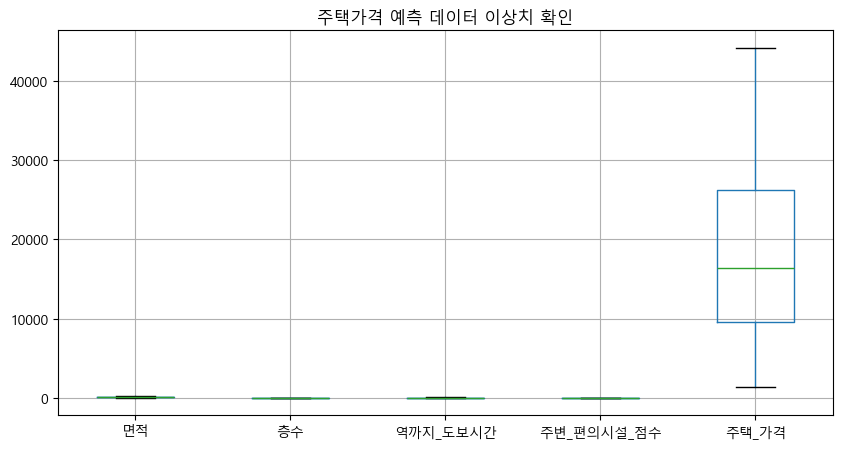

In [21]:
plt.figure(figsize=(10, 5))
plt.title("주택가격 예측 데이터 이상치 확인")
df_org.boxplot()

plt.show()


![alt text](image.png)
- 점이 안 보이니 이상치 없다고 볼 수 있음.

### 상관관계 확인하기

In [22]:
### 특성들 간의 관계 확인
# - 종속변수를 기준으로 독립변수들과 비교 확인
#   (독립변수: "면적", "층수", "역까지_도보시간", "주변_편의시설_점수")
#   (종속변수: "주택_가격")
# - 선형성(회귀분석)을 띄는지 비선형성(분류분석)을 띄는지 확인
# - 상관관계표 및 상관관계도(시각화)로 표현

#### 상관관계표로 확인

In [23]:
correlation_matrix = df_org.corr()
correlation_matrix

,면적,층수,역까지_도보시간,주변_편의시설_점수,주택_가격
면적,1.000000,0.058629,-0.025361,0.050418,0.963063
층수,0.058629,1.000000,-0.029001,-0.013287,0.229850
역까지_도보시간,-0.025361,-0.029001,1.000000,-0.003508,-0.117005
주변_편의시설_점수,0.050418,-0.013287,-0.003508,1.000000,0.091508
주택_가격,0.963063,0.229850,-0.117005,0.091508,1.000000


#### 상관관계도(시각화) 확인

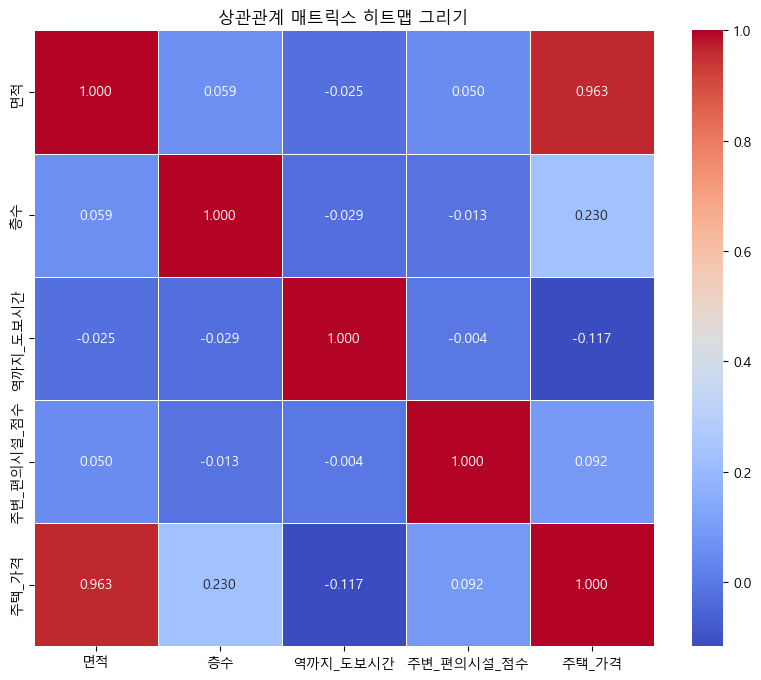

In [24]:
plt.figure(figsize=(10, 8))
plt.title("상관관계 매트릭스 히트맵 그리기")

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".3f", linewidths=0.5)

plt.show()

#### 산점행렬도 : 특성들간의 관계를 산점도(선형/비선형 분포) 확인

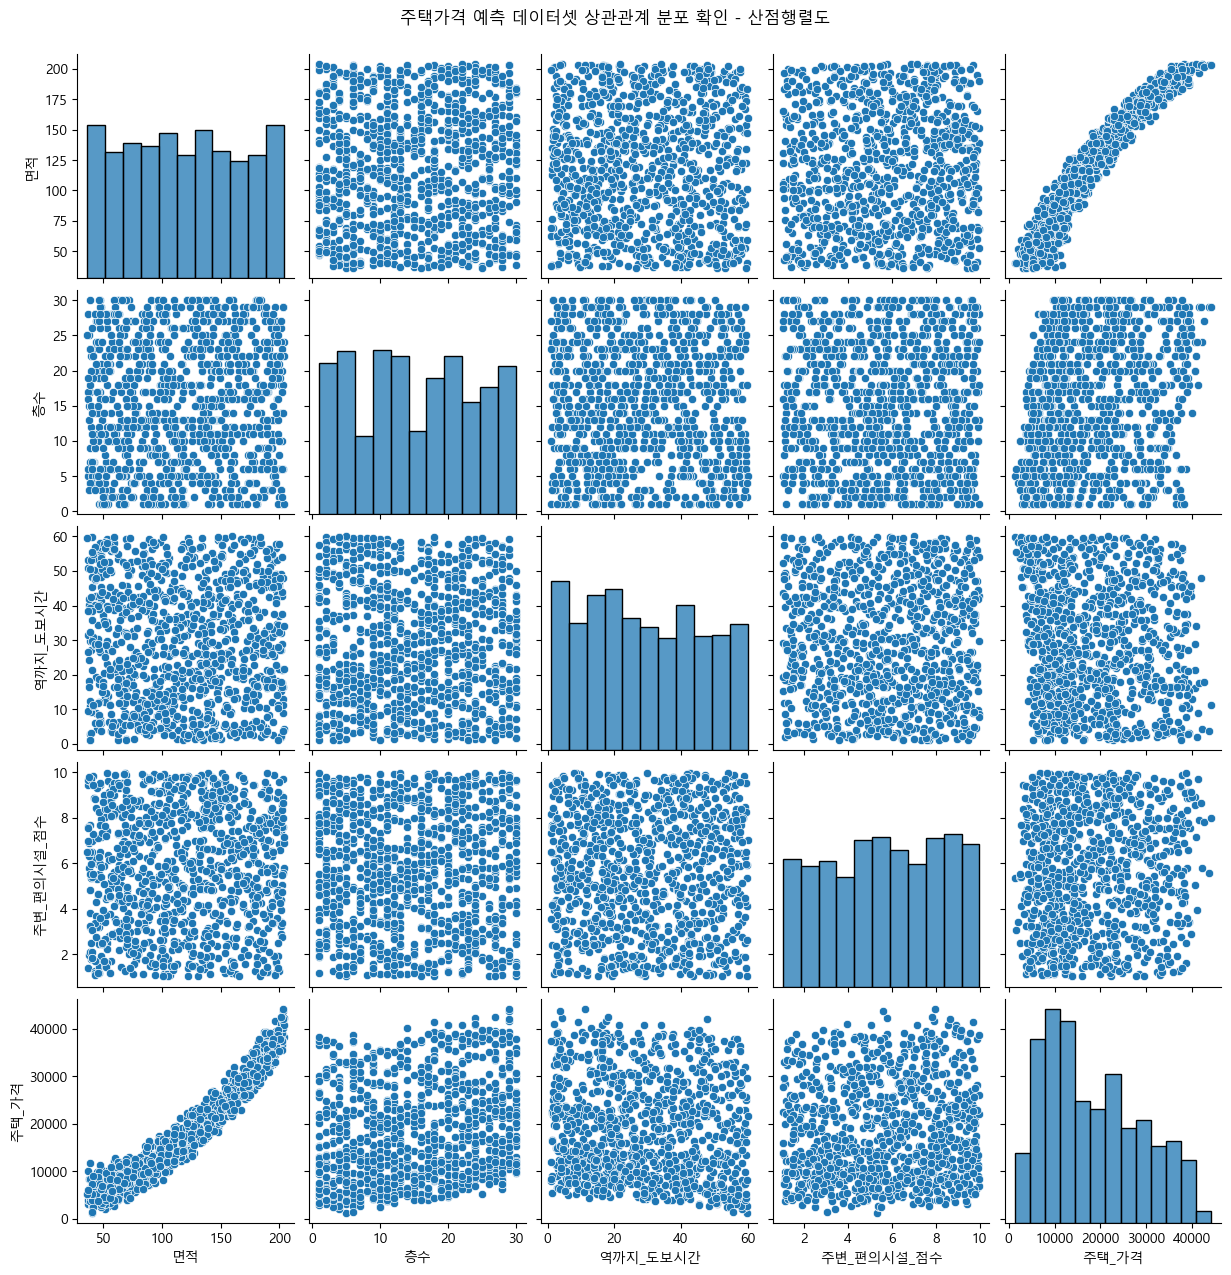

In [25]:
#산점행렬도 시각화 함수
sns.pairplot(df_org)

### 제목(pairplot 함수 사용시)
plt.suptitle("주택가격 예측 데이터셋 상관관계 분포 확인 - 산점행렬도", y=1.02)

plt.show()

### 상관관계 검증하기 (종속변수를 기준으로 독립변수들 간의 유의미성 확인)

In [26]:
### 유의미성 : p-value < 0.05
### 독립변수와 종속변수로 분리해야함
# - 독립변수 명 : X(대문자)
# - 종속변수 명 : y
X = df_org.drop(columns="주택_가격")
X = df_org.iloc[:, :-1] #  ,기준 왼쪽 행, 오른쪽을 열
y = df_org["주택_가격"]

X.shape, y.shape

((1000, 4), (1000,))

### 상관관계 검정하기 (스피어만 방식)

In [27]:
### 샘플로 독립변수 "면적"과 종속변수와의 유의미성 확인
s, p = spearmanr(X["면적"], y)
print(f"상관계수={s: .5f}, p-value={p: .5f}")
if p < 0.05:
    print("유의미하다")
if p >= 0.05:
    print("유의미하지않다")

상관계수= 0.97043, p-value= 0.00000
유의미하다


In [28]:
### 모든 독립변수와 종속변수 간의 유의미성(p-value)를 각각 확인하기
s, p = spearmanr(X["면적"], y)
print(f"상관계수={s: .5f}, p-value={p: .5f}")
if p < 0.05:
    print("유의미하다")
if p >= 0.05:
    print("유의미하지않다")

상관계수= 0.97043, p-value= 0.00000
유의미하다


In [29]:
# []로 써야함. 
cols = df_org.columns
for col in cols[0: len(cols)-1]:
    s, p = spearmanr(X[col], y)
    print(f"상관계수={s: .5f}, p-value={p: .5f}")
    if p < 0.05:
        print("p-value < 0.05 이므로 유의미하다")
    if p >= 0.05:
        print("p-value >= 0.05 이므로 유의미하지않다")

상관계수= 0.97043, p-value= 0.00000
p-value < 0.05 이므로 유의미하다
상관계수= 0.23822, p-value= 0.00000
p-value < 0.05 이므로 유의미하다
상관계수=-0.13078, p-value= 0.00003
p-value < 0.05 이므로 유의미하다
상관계수= 0.09136, p-value= 0.00383
p-value < 0.05 이므로 유의미하다


### 피어스만으로도 유의미성 확인

In [30]:

for col in X.columns:
    s, p = pearsonr(X[col], y)
    print(f"상관계수={s: .5f}, p-value={p: .5f}")
    if p < 0.05:
        print("p-value < 0.05 이므로 유의미하다")
    if p >= 0.05:
        print("p-value >= 0.05 이므로 유의미하지않다")

상관계수= 0.96306, p-value= 0.00000
p-value < 0.05 이므로 유의미하다
상관계수= 0.22985, p-value= 0.00000
p-value < 0.05 이므로 유의미하다
상관계수=-0.11700, p-value= 0.00021
p-value < 0.05 이므로 유의미하다
상관계수= 0.09151, p-value= 0.00378
p-value < 0.05 이므로 유의미하다


### 모델 훈련을 위한 데이터 분리하기(훈련 : 검증 : 테스트 = 6:2:2로 분리)

In [31]:
"""
사용 변수명 : X_train, y_train, X_val, y_val, X_test, y_test
"""
## 독립변수의 훈련,테스트 , 종속변수의 훈련,테스트 순서로 써야함!

# 훈련 : (검증+테스트) = 6:4
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4 ,random_state=42)

# 검증 : 테스트 = 5:5
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5 ,random_state=42)

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)


(600, 4) (600,)
(200, 4) (200,)
(200, 4) (200,)


### 데이터스케일링(표준화) 처리하기(훈련, 검증, 테스트 모두 처리)

In [61]:
### 변수명 : X_train_scaled, X_val_scaled, X_test_scaled
scaler = StandardScaler()
# 훈련데이터만 패턴 분석
scaler.fit(X_train)
#변환시키기
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape)


(600, 4) (200, 4) (200, 4)
